# Module 14 — Information Theory

This notebook is the runnable companion to the concept guide: read [README.md](README.md) first, or keep
it open alongside. Every section below mirrors a numbered section of the guide. We measure the surprise
of coin flips, dice and a rare diagnosis; draw the binary entropy curve and compute the entropy of English
letters; build a Huffman coder with `heapq` and compare its expected length with the entropy; compute
cross-entropy and KL divergence and watch forward and reverse KL fit a Gaussian to two-humped data in
opposite ways; estimate mutual information from a table and from samples; draw Jensen's inequality and the
ELBO; solve a maximum-entropy problem; compute information gain for a triage table and for the iris data;
sweep the temperature of a softmax; and finish with the capacity of a noisy channel.

Everything is plain NumPy first; library calls (`scipy.stats.entropy`, `mutual_info_regression`,
`DecisionTreeClassifier`) appear only afterwards, to confirm the hand computation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)

def entropy_bits(p):
    # H(p) = -sum p log2 p, with the convention 0 log 0 = 0 (terms with p = 0 are dropped)
    p = np.asarray(p, dtype=float).ravel()
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

def binary_entropy(p):
    return entropy_bits([p, 1 - p])

LN2 = np.log(2)   # 1 bit = ln 2 nats;  1 nat = 1/ln 2 = 1.4427 bits

## 1. Information as surprise

The information in an outcome of probability $p$ is $I = -\log_2 p$ bits (or $-\ln p$ nats). It is zero
for a certain event, grows without bound as $p \to 0$, and is *additive* for independent events because
their probabilities multiply. We check these on a biased coin, dice and a rare disease.

event                                             bits     nats
biased coin: heads, p = 0.9                     0.1520   0.1054
biased coin: tails, p = 0.1                     3.3219   2.3026
fair die: one face, p = 1/6                     2.5850   1.7918
two dice: one outcome, p = 1/36                 5.1699   3.5835
rare disease: 'you have it', p = 1e-4          13.2877   9.2103
rare disease: 'you do not', p = 0.9999          0.0001   0.0001

additivity: I(1/36) = 5.1699  =  I(1/6) + I(1/6) = 5.1699
unit conversion: 1 nat = 1.4427 bits,  1 bit = 0.6931 nats
twenty yes/no questions distinguish up to 2^20 = 1,048,576 objects


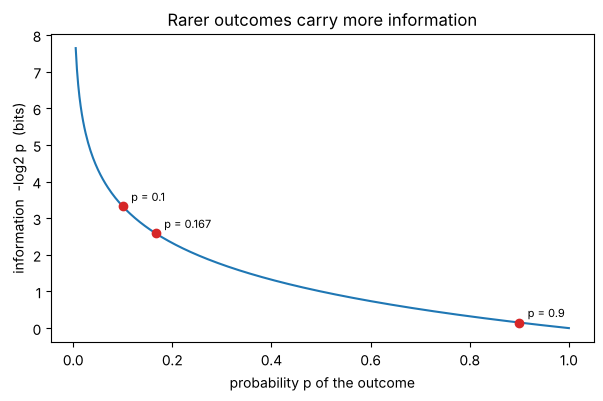

In [2]:
def surprise_bits(p):
    return -np.log2(p)

events = [
    ("biased coin: heads, p = 0.9",            0.9),
    ("biased coin: tails, p = 0.1",            0.1),
    ("fair die: one face, p = 1/6",            1/6),
    ("two dice: one outcome, p = 1/36",        1/36),
    ("rare disease: 'you have it', p = 1e-4",  1e-4),
    ("rare disease: 'you do not', p = 0.9999", 1 - 1e-4),
]
print(f"{'event':45s} {'bits':>8s} {'nats':>8s}")
for name, p in events:
    print(f"{name:45s} {surprise_bits(p):8.4f} {-np.log(p):8.4f}")

print(f"\nadditivity: I(1/36) = {surprise_bits(1/36):.4f}  =  I(1/6) + I(1/6) = {2 * surprise_bits(1/6):.4f}")
print(f"unit conversion: 1 nat = {1/LN2:.4f} bits,  1 bit = {LN2:.4f} nats")
print(f"twenty yes/no questions distinguish up to 2^20 = {2**20:,} objects")

p_grid = np.linspace(0.005, 1, 400)
plt.plot(p_grid, -np.log2(p_grid))
for name, p in events[:3]:
    plt.plot(p, -np.log2(p), "o", color="C3")
    plt.annotate(f"p = {p:.3g}", (p, -np.log2(p)), textcoords="offset points", xytext=(6, 4), fontsize=8)
plt.xlabel("probability p of the outcome"); plt.ylabel("information  -log2 p  (bits)")
plt.title("Rarer outcomes carry more information"); plt.show()

Tails on the 90/10 coin carries $3.32$ bits, twenty times the $0.15$ bits of heads: the logarithm
stretches small probabilities. Being told you *do not* have a one-in-ten-thousand disease carries
$0.00014$ bits — you already knew. And the two-dice outcome carries exactly twice the information of one
die, which is the additivity that forces the logarithm in the first place.

## 2. Entropy: average surprise

$H(X) = -\sum_x p(x)\log_2 p(x)$ is the expected surprise. For a Bernoulli$(p)$ variable it is the binary
entropy $H_b(p)$, maximal (1 bit) at $p = \tfrac12$. We draw it, compute the entropy of a loaded die, and
then the entropy of English letters from their frequencies — compared with the uniform bound $\log_2 26$.

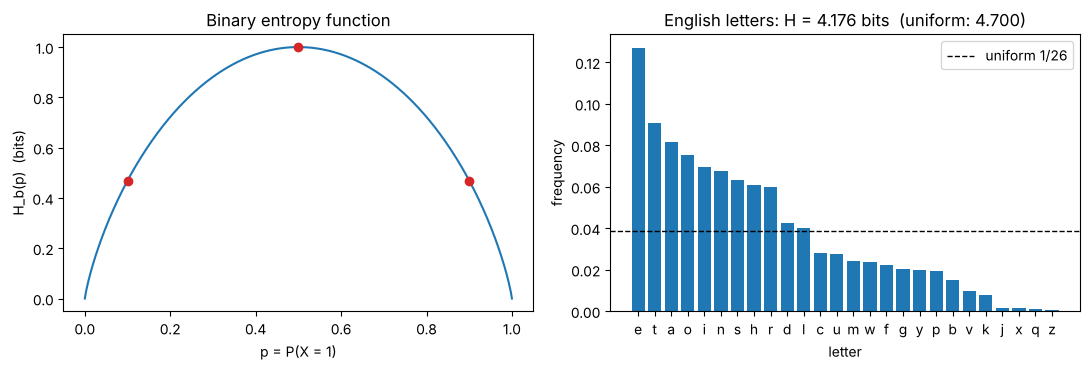

H_b(0.5) = 1.0000 bits
H_b(0.9) = 0.4690 bits
H_b(0.99) = 0.0808 bits
H_b(0.999) = 0.0114 bits

fair die: H = log2 6 = 2.5850 bits;   loaded die [0.5 0.1 0.1 0.1 0.1 0.1]: H = 2.1610 bits
English letters: H = 4.1758 bits/letter;  uniform bound log2 26 = 4.7004;  'effective alphabet' 2^H = 18.1 letters


scipy.stats.entropy(p_letters, base=2) = 4.1758


In [3]:
# standard English letter frequencies in percent (a widely used table; sums to ~100)
letter_freq = {'a': 8.167, 'b': 1.492, 'c': 2.782, 'd': 4.253, 'e': 12.702, 'f': 2.228, 'g': 2.015,
               'h': 6.094, 'i': 6.966, 'j': 0.153, 'k': 0.772, 'l': 4.025, 'm': 2.406, 'n': 6.749,
               'o': 7.507, 'p': 1.929, 'q': 0.095, 'r': 5.987, 's': 6.327, 't': 9.056, 'u': 2.758,
               'v': 0.978, 'w': 2.360, 'x': 0.150, 'y': 1.974, 'z': 0.074}
letters = np.array(list(letter_freq.keys()))
p_letters = np.array(list(letter_freq.values())); p_letters = p_letters / p_letters.sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ps = np.linspace(0, 1, 401)
ax1.plot(ps, [binary_entropy(p) for p in ps])
for p in (0.1, 0.5, 0.9):
    ax1.plot(p, binary_entropy(p), "o", color="C3")
ax1.set_xlabel("p = P(X = 1)"); ax1.set_ylabel("H_b(p)  (bits)"); ax1.set_title("Binary entropy function")
order = np.argsort(p_letters)[::-1]
ax2.bar(letters[order], p_letters[order])
ax2.axhline(1/26, color="k", ls="--", lw=1, label="uniform 1/26")
ax2.set_xlabel("letter"); ax2.set_ylabel("frequency")
ax2.set_title(f"English letters: H = {entropy_bits(p_letters):.3f} bits  (uniform: {np.log2(26):.3f})")
ax2.legend(); plt.tight_layout(); plt.show()

for p in (0.5, 0.9, 0.99, 0.999):
    print(f"H_b({p}) = {binary_entropy(p):.4f} bits")
loaded = np.array([0.5, 0.1, 0.1, 0.1, 0.1, 0.1])
print(f"\nfair die: H = log2 6 = {np.log2(6):.4f} bits;   loaded die {loaded}: H = {entropy_bits(loaded):.4f} bits")
H_letters = entropy_bits(p_letters)
print(f"English letters: H = {H_letters:.4f} bits/letter;  uniform bound log2 26 = {np.log2(26):.4f};  "
      f"'effective alphabet' 2^H = {2**H_letters:.1f} letters")

# the library version agrees (scipy.stats.entropy returns nats by default)
from scipy.stats import entropy as sp_entropy
print(f"scipy.stats.entropy(p_letters, base=2) = {sp_entropy(p_letters, base=2):.4f}")

Single-letter frequencies alone bring English from $4.70$ to $4.18$ bits per letter — as unpredictable as a
uniform choice among about 18 letters rather than 26. Shannon's guessing experiments, which use long
context, push the figure down to roughly 1 bit per letter; the gap between $4.18$ and $1$ is the information
carried by *spelling and grammar*, which a unigram model cannot see and a language model can.

**Try it yourself:** replace `loaded` by `[0.95, 0.01, 0.01, 0.01, 0.01, 0.01]` — how many bits does the die
produce per roll now, and how does that compare with $H_b(0.05)$?

### Joint and conditional entropy, and the chain rule

For the weather–umbrella table of the guide we compute $H(X)$, $H(Y)$, $H(X, Y)$, then $H(Y \mid X)$ two
ways: by the chain rule $H(X, Y) - H(X)$ and directly as $\sum_x p(x)\,H(Y \mid X = x)$.

In [4]:
# rows: X = weather (sun, rain); columns: Y = umbrella (no, yes)
joint = np.array([[0.5, 0.1],
                  [0.1, 0.3]])
p_x, p_y = joint.sum(axis=1), joint.sum(axis=0)
H_X, H_Y, H_XY = entropy_bits(p_x), entropy_bits(p_y), entropy_bits(joint)
print(f"H(X) = {H_X:.4f}   H(Y) = {H_Y:.4f}   H(X,Y) = {H_XY:.4f} bits")
print(f"chain rule:   H(Y|X) = H(X,Y) - H(X) = {H_XY - H_X:.4f}")

cond_direct = sum(p_x[i] * entropy_bits(joint[i] / p_x[i]) for i in range(2))
for i, w in enumerate(["sun", "rain"]):
    print(f"   H(Y | X = {w:4s}) = {entropy_bits(joint[i] / p_x[i]):.4f}   (weight p(x) = {p_x[i]:.1f})")
print(f"direct:       H(Y|X) = sum_x p(x) H(Y|X=x) = {cond_direct:.4f}")
print(f"\nconditioning reduces uncertainty: H(Y) - H(Y|X) = {H_Y - (H_XY - H_X):.4f} bits  (= the mutual information, Section 5)")
print(f"independent check: if X, Y were independent, H(X,Y) would be H(X) + H(Y) = {H_X + H_Y:.4f} > {H_XY:.4f}")

H(X) = 0.9710   H(Y) = 0.9710   H(X,Y) = 1.6855 bits
chain rule:   H(Y|X) = H(X,Y) - H(X) = 0.7145
   H(Y | X = sun ) = 0.6500   (weight p(x) = 0.6)
   H(Y | X = rain) = 0.8113   (weight p(x) = 0.4)
direct:       H(Y|X) = sum_x p(x) H(Y|X=x) = 0.7145

conditioning reduces uncertainty: H(Y) - H(Y|X) = 0.2564 bits  (= the mutual information, Section 5)
independent check: if X, Y were independent, H(X,Y) would be H(X) + H(Y) = 1.9419 > 1.6855


### Differential entropy and why it is not "information"

For a Gaussian, $h = \tfrac12\log_2(2\pi e\sigma^2)$ bits. It goes *negative* for small $\sigma$, and if you
quantise the variable into bins of width $\Delta$ the discrete entropy is about $h + \log_2(1/\Delta)$,
which diverges as the bins shrink. Only differences of differential entropies (KL, mutual information) are
meaningful.

In [5]:
from scipy.stats import norm

def gaussian_diff_entropy_bits(sigma):
    return 0.5 * np.log2(2 * np.pi * np.e * sigma**2)

for s in (0.1, 1.0, 10.0):
    print(f"sigma = {s:5.1f}: differential entropy h = {gaussian_diff_entropy_bits(s):7.3f} bits  ({gaussian_diff_entropy_bits(s) * LN2:6.3f} nats)")

print("\nquantised standard normal (exact bin probabilities from the CDF):")
for delta in (1.0, 0.1, 0.01):
    edges = np.arange(-12, 12 + delta, delta)
    probs = np.diff(norm.cdf(edges))
    H_disc = entropy_bits(probs)
    print(f"  bin width {delta:5.2f}: discrete entropy {H_disc:7.3f} bits   vs   h + log2(1/delta) = {gaussian_diff_entropy_bits(1.0) + np.log2(1/delta):7.3f}")

sigma =   0.1: differential entropy h =  -1.275 bits  (-0.884 nats)
sigma =   1.0: differential entropy h =   2.047 bits  ( 1.419 nats)
sigma =  10.0: differential entropy h =   5.369 bits  ( 3.722 nats)

quantised standard normal (exact bin probabilities from the CDF):
  bin width  1.00: discrete entropy   2.105 bits   vs   h + log2(1/delta) =   2.047
  bin width  0.10: discrete entropy   5.370 bits   vs   h + log2(1/delta) =   5.369
  bin width  0.01: discrete entropy   8.691 bits   vs   h + log2(1/delta) =   8.691


The discrete entropy grows by $\log_2 10 = 3.32$ bits each time the bins get ten times finer: there is no
finite "number of bits in a real number". The differential entropy is what remains after subtracting that
divergent part, which is why it can be negative without contradiction.

## 3. Source coding: Huffman codes and the entropy bound

Shannon: every prefix code has expected length $L \ge H$, and an optimal one has $L < H + 1$. Huffman's
algorithm — repeatedly merge the two least probable symbols — builds an optimal prefix code. We implement
it with a priority queue, check the Kraft sum $\sum_i 2^{-\ell_i}$, and compare $L$ with $H$ for the
five-symbol example of the guide and for English letters.

In [6]:
import heapq, itertools

def huffman_code(probs):
    # probs: dict symbol -> probability.  Returns dict symbol -> binary codeword (string).
    counter = itertools.count()                       # tie-breaker so tuples never compare nodes
    heap = [(p, next(counter), sym) for sym, p in probs.items()]
    heapq.heapify(heap)
    while len(heap) > 1:
        p1, _, left = heapq.heappop(heap)             # the two least probable nodes ...
        p2, _, right = heapq.heappop(heap)
        heapq.heappush(heap, (p1 + p2, next(counter), (left, right)))   # ... become one node
    root = heap[0][2]
    codes = {}
    def walk(node, prefix):
        if isinstance(node, tuple):
            walk(node[0], prefix + "0"); walk(node[1], prefix + "1")
        else:
            codes[node] = prefix or "0"
    walk(root, "")
    return codes

def expected_length(probs, codes):
    return sum(p * len(codes[s]) for s, p in probs.items())

def kraft_sum(codes):
    return sum(2.0 ** -len(c) for c in codes.values())

p5 = {"A": 0.4, "B": 0.2, "C": 0.2, "D": 0.1, "E": 0.1}
codes5 = huffman_code(p5)
print("five-symbol source:")
for s in p5:
    print(f"  {s}: p = {p5[s]:.1f}   code = {codes5[s]:4s}   length {len(codes5[s])}   ideal -log2 p = {-np.log2(p5[s]):.3f}")
H5 = entropy_bits(list(p5.values()))
print(f"  entropy H = {H5:.4f} bits   expected length L = {expected_length(p5, codes5):.4f} bits   Kraft sum = {kraft_sum(codes5):.3f}")
print(f"  overhead L - H = {expected_length(p5, codes5) - H5:.4f} bits ({100 * (expected_length(p5, codes5) / H5 - 1):.1f}%)   fixed-length code would need {int(np.ceil(np.log2(5)))} bits")

dyadic = {"A": 0.5, "B": 0.25, "C": 0.125, "D": 0.0625, "E": 0.0625}
cd = huffman_code(dyadic)
print(f"\ndyadic source: L = {expected_length(dyadic, cd):.4f} = H = {entropy_bits(list(dyadic.values())):.4f} bits  (powers of two -> no overhead)")

p_en = {str(s): float(p) for s, p in zip(letters, p_letters)}
codes_en = huffman_code(p_en)
L_en = expected_length(p_en, codes_en)
print(f"\nEnglish letters: H = {H_letters:.4f}   Huffman L = {L_en:.4f} bits/letter   Kraft sum = {kraft_sum(codes_en):.3f}   fixed-length: 5 bits")
print("  shortest codes:", {s: codes_en[s] for s in map(str, letters[order][:4])})
print("  longest codes: ", {s: codes_en[s] for s in map(str, letters[order][-3:])})

five-symbol source:
  A: p = 0.4   code = 11     length 2   ideal -log2 p = 1.322
  B: p = 0.2   code = 00     length 2   ideal -log2 p = 2.322
  C: p = 0.2   code = 01     length 2   ideal -log2 p = 2.322
  D: p = 0.1   code = 100    length 3   ideal -log2 p = 3.322
  E: p = 0.1   code = 101    length 3   ideal -log2 p = 3.322
  entropy H = 2.1219 bits   expected length L = 2.2000 bits   Kraft sum = 1.000
  overhead L - H = 0.0781 bits (3.7%)   fixed-length code would need 3 bits

dyadic source: L = 1.8750 = H = 1.8750 bits  (powers of two -> no overhead)

English letters: H = 4.1758   Huffman L = 4.2051 bits/letter   Kraft sum = 1.000   fixed-length: 5 bits
  shortest codes: {'e': '100', 't': '000', 'a': '1110', 'o': '1101'}
  longest codes:  {'x': '001001010', 'q': '001001001', 'z': '001001000'}


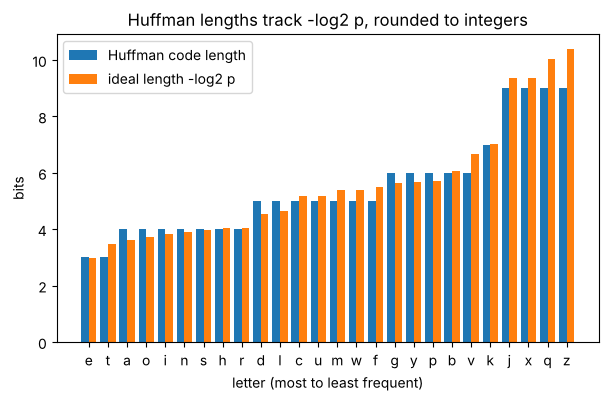

text of 98 letters:
  fixed 5-bit code   :   490 bits  (5.000 bits/letter)
  Huffman (unigram)  :   415 bits  (4.235 bits/letter)
  arithmetic (unigram):   414.3 bits  (4.228 bits/letter)  = total log-loss of the model + 2
  model entropy H    : 4.176 bits/letter (expected cost if the text really came from the unigram model)


In [7]:
lengths_en = np.array([len(codes_en[s]) for s in letters[order]])
ideal_en = -np.log2(p_letters[order])
xpos = np.arange(26)
plt.bar(xpos - 0.2, lengths_en, width=0.4, label="Huffman code length")
plt.bar(xpos + 0.2, ideal_en, width=0.4, label="ideal length -log2 p")
plt.xticks(xpos, letters[order]); plt.xlabel("letter (most to least frequent)"); plt.ylabel("bits")
plt.title("Huffman lengths track -log2 p, rounded to integers"); plt.legend(); plt.show()

# arithmetic coding: a whole text costs -sum log2 p(c) + 2 bits under the model -- no rounding per symbol
text = ("information is the resolution of uncertainty and a good model of the next symbol "
        "is a good compressor of the whole text")
chars = [c for c in text if c in letter_freq]
p_model = dict(zip(letters, p_letters))
bits_arith = -sum(np.log2(p_model[c]) for c in chars) + 2
bits_huff = sum(len(codes_en[c]) for c in chars)
n = len(chars)
print(f"text of {n} letters:")
print(f"  fixed 5-bit code   : {5 * n:5d} bits  ({5:.3f} bits/letter)")
print(f"  Huffman (unigram)  : {bits_huff:5d} bits  ({bits_huff / n:.3f} bits/letter)")
print(f"  arithmetic (unigram): {bits_arith:7.1f} bits  ({bits_arith / n:.3f} bits/letter)  = total log-loss of the model + 2")
print(f"  model entropy H    : {H_letters:.3f} bits/letter (expected cost if the text really came from the unigram model)")

Huffman gives "e" and "t" three-bit codes and "q" and "z" ten-bit codes; the integer lengths hug the ideal
$-\log_2 p$ from above, and the expected length lands within a few hundredths of a bit of the entropy. The
arithmetic coder removes even that rounding: its length *is* the model's log-loss on the text, plus two bits.
That identity is the reason a language model's cross-entropy loss, in bits, is literally a compression rate.

**Try it yourself:** replace the unigram model by the uniform distribution (`p_model = {c: 1/26 ...}`) and
recompute `bits_arith` — the cost should jump to exactly $\log_2 26 = 4.70$ bits per letter.

## 4. Cross-entropy and KL divergence

$$H(p, q) = -\sum_x p(x)\log q(x), \qquad D_{\mathrm{KL}}(p \,\|\, q) = \sum_x p(x)\log\frac{p(x)}{q(x)} = H(p, q) - H(p) \ge 0 .$$

We implement both with the right conventions ($0\log 0 = 0$; $p > 0, q = 0 \Rightarrow \infty$), check
Gibbs' inequality and the asymmetry on the guide's example, and verify against `scipy.stats.entropy(p, q)`.

In [8]:
def kl_bits(p, q):
    p, q = np.asarray(p, dtype=float).ravel(), np.asarray(q, dtype=float).ravel()
    mask = p > 0                                   # 0 log 0 = 0: terms with p = 0 contribute nothing
    if np.any(q[mask] == 0):
        return np.inf                              # the model calls a possible event impossible
    return float(np.sum(p[mask] * np.log2(p[mask] / q[mask])))

def cross_entropy_bits(p, q):
    return entropy_bits(p) + kl_bits(p, q)

p, q = np.array([0.9, 0.1]), np.array([0.5, 0.5])
print(f"KL(p||q) = {kl_bits(p, q):.4f} bits    KL(q||p) = {kl_bits(q, p):.4f} bits   -> asymmetric")
print(f"H(p) = {entropy_bits(p):.4f}   H(p,q) = H(p) + KL(p||q) = {cross_entropy_bits(p, q):.4f} bits  (a fair-coin code spends exactly 1 bit/symbol)")
print(f"H(q,p) = {cross_entropy_bits(q, p):.4f} bits")
print(f"Gibbs: KL(p||p) = {kl_bits(p, p):.4f};  KL for a uniform model = log2 n - H(p) = {np.log2(2) - entropy_bits(p):.4f}")
print(f"impossible event: KL([0.9, 0.1] || [1.0, 0.0]) = {kl_bits([0.9, 0.1], [1.0, 0.0])}")
print(f"\nscipy.stats.entropy(p, q, base=2) = {sp_entropy(p, q, base=2):.4f}   (KL(p||q); first argument is the 'truth')")

# the loss of a classifier is the cross-entropy between the one-hot label and its prediction
y_onehot = np.array([0, 1, 0]); q_pred = np.array([0.7, 0.2, 0.1])
print(f"\nclassifier predicts {q_pred}, label is class 2: loss = -log q[1] = {-np.log(q_pred[1]):.4f} nats = {cross_entropy_bits(y_onehot, q_pred):.4f} bits")

KL(p||q) = 0.5310 bits    KL(q||p) = 0.7370 bits   -> asymmetric
H(p) = 0.4690   H(p,q) = H(p) + KL(p||q) = 1.0000 bits  (a fair-coin code spends exactly 1 bit/symbol)
H(q,p) = 1.7370 bits
Gibbs: KL(p||p) = 0.0000;  KL for a uniform model = log2 n - H(p) = 0.5310
impossible event: KL([0.9, 0.1] || [1.0, 0.0]) = inf

scipy.stats.entropy(p, q, base=2) = 0.5310   (KL(p||q); first argument is the 'truth')

classifier predicts [0.7 0.2 0.1], label is class 2: loss = -log q[1] = 1.6094 nats = 2.3219 bits


### Forward vs reverse KL: mode-covering vs mode-seeking

Fit a single Gaussian $q = \mathcal{N}(\mu, \sigma^2)$ to a two-humped $p = \tfrac12\mathcal{N}(-3, 1) +
\tfrac12\mathcal{N}(3, 1)$ by minimising either $D_{\mathrm{KL}}(p \,\|\, q)$ (what maximum likelihood does)
or $D_{\mathrm{KL}}(q \,\|\, p)$ (what variational inference does). Both integrals are evaluated on a grid and
minimised numerically from the same starting point.

forward KL(p||q) minimiser: mu = -0.000, sigma = 3.162   KL = 0.4620 nats   (moment matching: mu 0, sigma sqrt(10) = 3.162)
reverse KL(q||p) minimiser: mu =  2.984, sigma = 1.023   KL = 0.6888 nats   (one hump)
cross-check: forward KL of the reverse fit = 7.861;  reverse KL of the forward fit = 0.932
reverse KL also has a broad *local* optimum at mu = -0.000, sigma = 2.747 with KL = 0.8402 > 0.6888


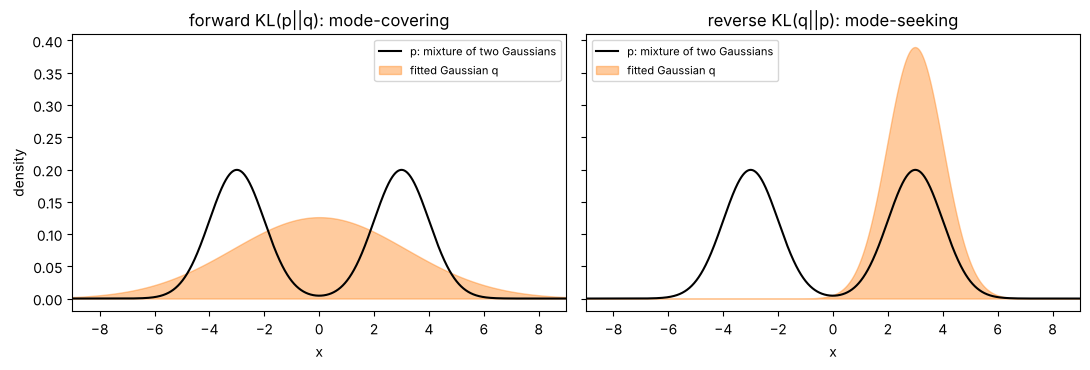

In [9]:
from scipy.optimize import minimize

x = np.linspace(-12, 12, 4001)
p_mix = 0.5 * norm.pdf(x, -3, 1) + 0.5 * norm.pdf(x, 3, 1)

def kl_grid(a, b):
    # KL(a || b) for two densities tabulated on the grid x, by the trapezoid rule
    mask = a > 1e-300
    a_safe = np.where(mask, a, 1.0); b_safe = np.maximum(b, 1e-300)
    return float(np.trapezoid(np.where(mask, a * np.log(a_safe / b_safe), 0.0), x))

def q_pdf(theta):
    mu, log_sigma = theta
    return norm.pdf(x, mu, np.exp(log_sigma))

theta0 = np.array([1.0, 0.0])                 # start at mu = 1, sigma = 1 for both fits
fwd = minimize(lambda th: kl_grid(p_mix, q_pdf(th)), theta0, method="Nelder-Mead")
rev = minimize(lambda th: kl_grid(q_pdf(th), p_mix), theta0, method="Nelder-Mead")
mu_f, sig_f = fwd.x[0], np.exp(fwd.x[1]); mu_r, sig_r = rev.x[0], np.exp(rev.x[1])
print(f"forward KL(p||q) minimiser: mu = {mu_f:6.3f}, sigma = {sig_f:.3f}   KL = {fwd.fun:.4f} nats   (moment matching: mu 0, sigma sqrt(10) = {np.sqrt(10):.3f})")
print(f"reverse KL(q||p) minimiser: mu = {mu_r:6.3f}, sigma = {sig_r:.3f}   KL = {rev.fun:.4f} nats   (one hump)")
print(f"cross-check: forward KL of the reverse fit = {kl_grid(p_mix, q_pdf(rev.x)):.3f};  reverse KL of the forward fit = {kl_grid(q_pdf(fwd.x), p_mix):.3f}")
broad = minimize(lambda th: kl_grid(q_pdf(th), p_mix), np.array([0.0, np.log(3.0)]), method="Nelder-Mead")
print(f"reverse KL also has a broad *local* optimum at mu = {broad.x[0]:.3f}, sigma = {np.exp(broad.x[1]):.3f} with KL = {broad.fun:.4f} > {rev.fun:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, th, name in zip(axes, (fwd.x, rev.x), ("forward KL(p||q): mode-covering", "reverse KL(q||p): mode-seeking")):
    ax.plot(x, p_mix, "k", label="p: mixture of two Gaussians")
    ax.fill_between(x, q_pdf(th), alpha=0.4, color="C1", label="fitted Gaussian q")
    ax.set_title(name); ax.set_xlabel("x"); ax.set_xlim(-9, 9); ax.legend(fontsize=8)
axes[0].set_ylabel("density"); plt.tight_layout(); plt.show()

Forward KL forces $q$ to put mass wherever $p$ has it (otherwise $\log(p/q)$ explodes), so the fit is one
broad Gaussian over both humps with most of its mass in the empty middle. Reverse KL punishes $q$ only for
mass where $p$ is small, so it hugs a single hump and ignores half the data; the other hump is an equally
good optimum, and a wide Gaussian in the middle is a *worse* local optimum that a poorly initialised optimiser
can get stuck in. This is the quantitative content of "VI approximations are too narrow".

**Try it yourself:** change `theta0` to `[-1.0, 0.0]` — the reverse fit should jump to the *left* hump, while
the forward fit lands on the same broad Gaussian. Then try `[0.0, np.log(3.0)]`.

### KL between Gaussians: closed form vs Monte Carlo

$$D_{\mathrm{KL}}\big(\mathcal{N}(\mu_1, \sigma_1^2)\,\|\,\mathcal{N}(\mu_2, \sigma_2^2)\big) = \log\frac{\sigma_2}{\sigma_1} + \frac{\sigma_1^2 + (\mu_1 - \mu_2)^2}{2\sigma_2^2} - \frac12 .$$

In [10]:
def kl_gauss(m1, s1, m2, s2):
    return np.log(s2 / s1) + (s1**2 + (m1 - m2)**2) / (2 * s2**2) - 0.5

n_mc = 200_000
for (m1, s1, m2, s2) in [(0, 1, 1, 2), (1, 2, 0, 1), (0, 1, 0, 1), (0, 1, 1, 1)]:
    xs = rng.normal(m1, s1, n_mc)
    log_ratio = norm.logpdf(xs, m1, s1) - norm.logpdf(xs, m2, s2)
    mc, se = log_ratio.mean(), log_ratio.std() / np.sqrt(n_mc)
    print(f"KL(N({m1},{s1}^2) || N({m2},{s2}^2)): closed form {kl_gauss(m1, s1, m2, s2):.4f} nats   Monte Carlo {mc:.4f} +/- {se:.4f}")
print(f"\nVAE regulariser KL(N(mu, sigma^2) || N(0,1)) for mu = 0.5, sigma = 0.8: {kl_gauss(0.5, 0.8, 0, 1):.4f} nats"
      f"  = 0.5 (mu^2 + sigma^2 - 1 - log sigma^2) = {0.5 * (0.25 + 0.64 - 1 - np.log(0.64)):.4f}")

KL(N(0,1^2) || N(1,2^2)): closed form 0.4431 nats   Monte Carlo 0.4413 +/- 0.0013
KL(N(1,2^2) || N(0,1^2)): closed form 1.3069 nats   Monte Carlo 1.3039 +/- 0.0065
KL(N(0,1^2) || N(0,1^2)): closed form 0.0000 nats   Monte Carlo 0.0000 +/- 0.0000
KL(N(0,1^2) || N(1,1^2)): closed form 0.5000 nats   Monte Carlo 0.4985 +/- 0.0022

VAE regulariser KL(N(mu, sigma^2) || N(0,1)) for mu = 0.5, sigma = 0.8: 0.1681 nats  = 0.5 (mu^2 + sigma^2 - 1 - log sigma^2) = 0.1681


The narrow distribution is cheap to describe with the wide one ($0.443$ nats) but not the other way round
($1.307$ nats), and the Monte Carlo estimates agree with the formula to within their standard errors. The
last line is the per-dimension KL term of every variational autoencoder.

## 5. Mutual information

$I(X; Y) = H(X) + H(Y) - H(X, Y) = D_{\mathrm{KL}}\big(p(x,y)\,\|\,p(x)p(y)\big)$. First from the joint
table of the diagnostic test (prevalence 1%, sensitivity 0.99, specificity 0.95), then *estimated* from
samples of a relation with zero correlation but strong dependence — including the bias of the plug-in
estimate and a shuffle null.

In [11]:
def mutual_information_bits(joint):
    joint = np.asarray(joint, dtype=float)
    return entropy_bits(joint.sum(axis=1)) + entropy_bits(joint.sum(axis=0)) - entropy_bits(joint)

prev, se, sp = 0.01, 0.99, 0.95
J = np.array([[se * prev,       (1 - se) * prev],        # rows: diseased, healthy
              [(1 - sp) * (1 - prev), sp * (1 - prev)]])  # cols: test +, test -
H_D = entropy_bits(J.sum(axis=1))
print(f"joint table (D/H x +/-):\n{J}")
print(f"H(D) = {H_D:.4f}   H(T) = {entropy_bits(J.sum(axis=0)):.4f}   H(D,T) = {entropy_bits(J):.4f} bits")
I_DT = mutual_information_bits(J)
print(f"I(D;T) = {I_DT:.4f} bits = {100 * I_DT / H_D:.1f}% of the uncertainty about disease status")
print(f"umbrella table: I(X;Y) = {mutual_information_bits(joint):.4f} bits  (matches Section 2)")

def test_info(se, sp, prev=0.01):
    J = np.array([[se * prev, (1 - se) * prev], [(1 - sp) * (1 - prev), sp * (1 - prev)]])
    return mutual_information_bits(J)
print("\ninformation carried by different tests at 1% prevalence:")
for se_, sp_ in [(0.99, 0.95), (0.80, 0.99), (0.99, 0.99), (0.90, 0.90)]:
    print(f"  sensitivity {se_:.2f}, specificity {sp_:.2f}: I = {test_info(se_, sp_):.4f} bits  ({100 * test_info(se_, sp_) / H_D:.0f}% of H(D))")

joint table (D/H x +/-):
[[9.900e-03 1.000e-04]
 [4.950e-02 9.405e-01]]
H(D) = 0.0808   H(T) = 0.3251   H(D,T) = 0.3651 bits
I(D;T) = 0.0407 bits = 50.4% of the uncertainty about disease status
umbrella table: I(X;Y) = 0.2564 bits  (matches Section 2)

information carried by different tests at 1% prevalence:
  sensitivity 0.99, specificity 0.95: I = 0.0407 bits  (50% of H(D))
  sensitivity 0.80, specificity 0.99: I = 0.0423 bits  (52% of H(D))
  sensitivity 0.99, specificity 0.99: I = 0.0595 bits  (74% of H(D))
  sensitivity 0.90, specificity 0.90: I = 0.0249 bits  (31% of H(D))


correlation(X, Y) = +0.0217   (essentially zero)
plug-in MI with 10x10 bins = 1.3541 bits
shuffle null (Y permuted, 200 times): mean 0.0119, max 0.0178 bits   <- what independence looks like with this estimator
Miller-Madow bias estimate (B-1)^2 / (2 N ln 2) = 0.0117 bits   (close to the null mean)


sklearn k-NN estimator: 1.8146 bits

Gaussian rho = 0.9: exact I = 1.1980 bits;  binned (10 bins) 0.9439;  k-NN 1.1838 bits


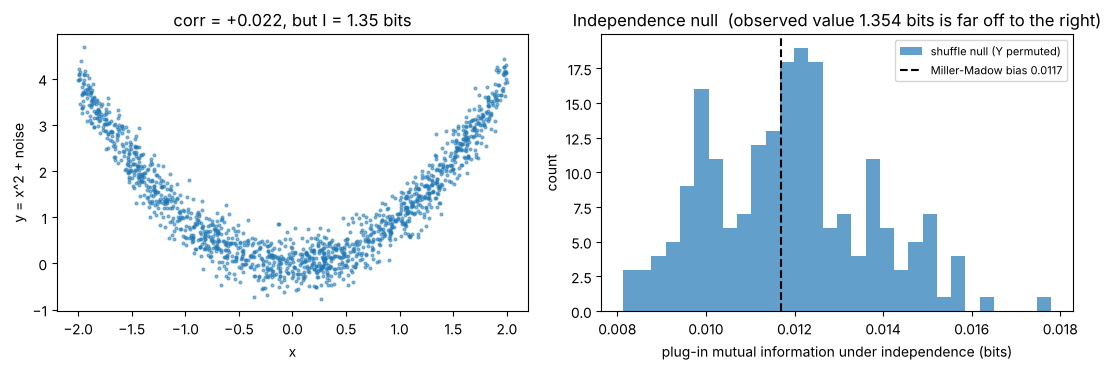

In [12]:
# estimating MI from samples: Y = X^2 + noise has zero correlation but strong dependence
n = 5_000
xs = rng.uniform(-2, 2, n)
ys = xs**2 + 0.3 * rng.normal(size=n)

def mi_binned_bits(x, y, bins=10):
    counts, _, _ = np.histogram2d(x, y, bins=bins)
    return mutual_information_bits(counts / counts.sum())

bins = 10
mi_obs = mi_binned_bits(xs, ys, bins)
null = np.array([mi_binned_bits(xs, rng.permutation(ys), bins) for _ in range(200)])
mm_bias = (bins - 1) * (bins - 1) / (2 * n * LN2)          # Miller-Madow first-order bias of the plug-in estimate
print(f"correlation(X, Y) = {np.corrcoef(xs, ys)[0, 1]:+.4f}   (essentially zero)")
print(f"plug-in MI with {bins}x{bins} bins = {mi_obs:.4f} bits")
print(f"shuffle null (Y permuted, 200 times): mean {null.mean():.4f}, max {null.max():.4f} bits   <- what independence looks like with this estimator")
print(f"Miller-Madow bias estimate (B-1)^2 / (2 N ln 2) = {mm_bias:.4f} bits   (close to the null mean)")

from sklearn.feature_selection import mutual_info_regression
mi_knn = mutual_info_regression(xs.reshape(-1, 1), ys, random_state=0)[0] / LN2
print(f"sklearn k-NN estimator: {mi_knn:.4f} bits")

# Gaussian pair with rho = 0.9: exact MI = -0.5 log2(1 - rho^2)
rho = 0.9
g = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], size=n)
print(f"\nGaussian rho = {rho}: exact I = {-0.5 * np.log2(1 - rho**2):.4f} bits;  binned ({bins} bins) {mi_binned_bits(g[:, 0], g[:, 1], bins):.4f};"
      f"  k-NN {mutual_info_regression(g[:, :1], g[:, 1], random_state=0)[0] / LN2:.4f} bits")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.scatter(xs[:1500], ys[:1500], s=4, alpha=0.5)
ax1.set_xlabel("x"); ax1.set_ylabel("y = x^2 + noise"); ax1.set_title(f"corr = {np.corrcoef(xs, ys)[0, 1]:+.3f}, but I = {mi_obs:.2f} bits")
ax2.hist(null, bins=30, alpha=0.7, label="shuffle null (Y permuted)")
ax2.axvline(mm_bias, color="k", ls="--", label=f"Miller-Madow bias {mm_bias:.4f}")
ax2.set_xlabel("plug-in mutual information under independence (bits)"); ax2.set_ylabel("count")
ax2.set_title(f"Independence null  (observed value {mi_obs:.3f} bits is far off to the right)")
ax2.legend(fontsize=8); plt.tight_layout(); plt.show()

Correlation sees nothing ($+0.02$); mutual information sees more than a bit of dependence. But notice the
null: with $10 \times 10$ bins and 5,000 points, *independent* data still produce about $0.012$ bits of
spurious information, in line with the Miller–Madow formula, and with fewer samples or more bins that bias
grows quickly — never read a small positive estimate as evidence of dependence without a null. For the
correlated Gaussians the coarse binning *under*-estimates the exact $1.198$ bits, while the
$k$-nearest-neighbour estimator comes closer: estimator choice matters.

**Try it yourself:** set `bins = 30` and re-run — the observed value and the null both rise. Which rises more?

## 6. Jensen's inequality and the ELBO

For concave $\log$, $\log\mathbb{E}[X] \ge \mathbb{E}[\log X]$: the chord lies below the curve. Applied to
$\log p(x) = \log\mathbb{E}_q[p(x, Z)/q(Z)]$ this gives the evidence lower bound, whose gap is
$D_{\mathrm{KL}}(q \,\|\, p(z \mid x))$. We draw the chord and then compute the ELBO of the guide's two-state
latent model for every $q$.

log2 E[X] = log2 2.5 = 1.3219   >=   E[log2 X] = 1.0000   (gap 0.3219 bits)
p(x) = 0.500, log p(x) = -0.6931 nats;  true posterior p(z|x) = [0.8 0.2]

 q(z=1)  E_q log p(x|z)  KL(q||prior)     ELBO      gap  KL(q||post)
   0.20         -1.3322        0.1927  -1.5249   0.8318       0.8318
   0.50         -0.9163        0.0000  -0.9163   0.2231       0.2231
   0.80         -0.5004        0.1927  -0.6931   0.0000      -0.0000
   0.95         -0.2925        0.4946  -0.7871   0.0939       0.0939


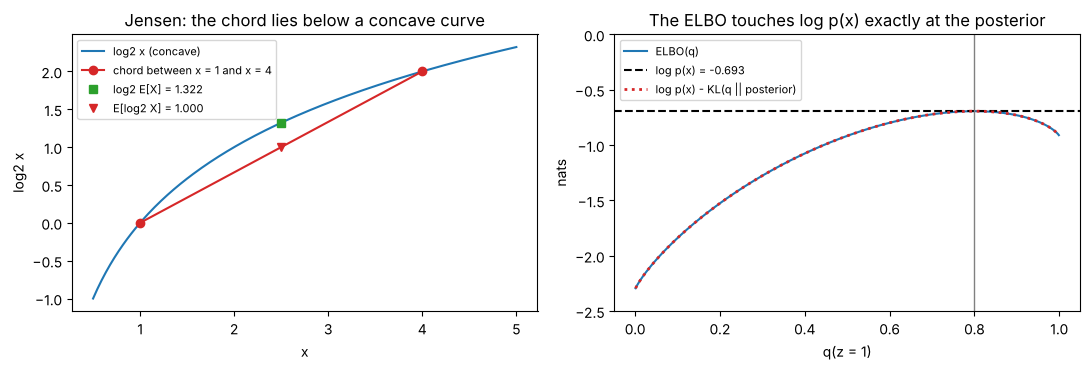

In [13]:
# Jensen: X is 1 or 4 with probability 1/2 each
xj = np.array([1.0, 4.0]); EX = xj.mean()
print(f"log2 E[X] = log2 {EX} = {np.log2(EX):.4f}   >=   E[log2 X] = {np.log2(xj).mean():.4f}   (gap {np.log2(EX) - np.log2(xj).mean():.4f} bits)")

# ELBO for a two-state latent variable: prior p(z) = (0.5, 0.5), likelihood p(x|z) = (0.8, 0.2)
prior = np.array([0.5, 0.5]); lik = np.array([0.8, 0.2])
evidence = float(prior @ lik); posterior = prior * lik / evidence
print(f"p(x) = {evidence:.3f}, log p(x) = {np.log(evidence):.4f} nats;  true posterior p(z|x) = {posterior}")

def kl_nats(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float); m = a > 0
    return float(np.sum(a[m] * np.log(a[m] / b[m])))

def elbo(q):
    q = np.asarray(q, float)
    return float(np.sum(q * np.log(lik)) - kl_nats(q, prior))     # E_q[log p(x|z)] - KL(q || prior)

print(f"\n{'q(z=1)':>7s} {'E_q log p(x|z)':>15s} {'KL(q||prior)':>13s} {'ELBO':>8s} {'gap':>8s} {'KL(q||post)':>12s}")
for q1 in (0.2, 0.5, 0.8, 0.95):
    q = np.array([q1, 1 - q1])
    print(f"{q1:7.2f} {np.sum(q * np.log(lik)):15.4f} {kl_nats(q, prior):13.4f} {elbo(q):8.4f} {np.log(evidence) - elbo(q):8.4f} {kl_nats(q, posterior):12.4f}")

q_grid = np.linspace(0.001, 0.999, 500)
elbos = np.array([elbo([q1, 1 - q1]) for q1 in q_grid])
gaps = np.array([kl_nats([q1, 1 - q1], posterior) for q1 in q_grid])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
u = np.linspace(0.5, 5, 200)
ax1.plot(u, np.log2(u), label="log2 x (concave)")
ax1.plot(xj, np.log2(xj), "o-", color="C3", label="chord between x = 1 and x = 4")
ax1.plot(EX, np.log2(EX), "s", color="C2", label=f"log2 E[X] = {np.log2(EX):.3f}")
ax1.plot(EX, np.log2(xj).mean(), "v", color="C3", label=f"E[log2 X] = {np.log2(xj).mean():.3f}")
ax1.set_xlabel("x"); ax1.set_ylabel("log2 x"); ax1.set_title("Jensen: the chord lies below a concave curve"); ax1.legend(fontsize=8)
ax2.plot(q_grid, elbos, label="ELBO(q)")
ax2.axhline(np.log(evidence), color="k", ls="--", label=f"log p(x) = {np.log(evidence):.3f}")
ax2.plot(q_grid, np.log(evidence) - gaps, ":", color="C3", lw=2, label="log p(x) - KL(q || posterior)")
ax2.axvline(posterior[0], color="gray", lw=1)
ax2.set_xlabel("q(z = 1)"); ax2.set_ylabel("nats"); ax2.set_title("The ELBO touches log p(x) exactly at the posterior")
ax2.set_ylim(-2.5, 0); ax2.legend(fontsize=8); plt.tight_layout(); plt.show()

The dotted curve $\log p(x) - D_{\mathrm{KL}}(q \,\|\, p(z \mid x))$ lies exactly on top of the ELBO: the
identity is exact, not approximate, and the bound is tight only at $q = p(z \mid x) = (0.8, 0.2)$. Moving
$q$ towards $0.95$ improves the reconstruction term but pays more KL to the prior; the posterior is where
the two balance. A VAE does this optimisation with a neural network producing $q$ and gradient steps instead
of a grid.

## 7. Maximum entropy: Jaynes' loaded die

A die averages $4.5$ instead of $3.5$ and nothing else is known. The maximum-entropy distribution with a
fixed mean has the exponential-family form $p(k) \propto e^{\lambda k}$; we solve for $\lambda$ with a root
finder and compare the entropy with other distributions that also have mean $4.5$.

mean 3.5: lambda = +0.0000   p = [0.1667 0.1667 0.1667 0.1667 0.1667 0.1667]   mean check 3.5000   H = 2.5850 bits
mean 4.5: lambda = +0.3710   p = [0.0544 0.0788 0.1142 0.1654 0.2398 0.3475]   mean check 4.5000   H = 2.3279 bits
mean 2.5: lambda = -0.3710   p = [0.3475 0.2398 0.1654 0.1142 0.0788 0.0544]   mean check 2.5000   H = 2.3279 bits

distributions with mean 4.5:
  max-ent  p ~ exp(lambda k)   mean = 4.50   H = 2.3279 bits
  (0, 0, 0, .5, .5, 0)         mean = 4.50   H = 1.0000 bits
  (.1, .1, .1, .1, .1, .5)     mean = 4.50   H = 2.1610 bits
ratio p(k+1)/p(k) = e^lambda = 1.4493 for every k;  entropy lost to the constraint: 0.2571 bits


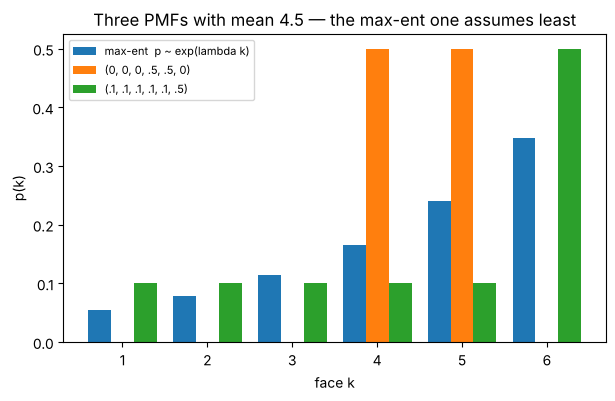

In [14]:
from scipy.optimize import brentq

faces = np.arange(1, 7)

def maxent_die(target_mean):
    mean_at = lambda lam: float(np.sum(faces * np.exp(lam * faces)) / np.sum(np.exp(lam * faces)))
    lam = brentq(lambda lam: mean_at(lam) - target_mean, -20, 20)
    w = np.exp(lam * faces)
    return lam, w / w.sum()

for m in (3.5, 4.5, 2.5):
    lam, p_me = maxent_die(m)
    print(f"mean {m}: lambda = {lam:+.4f}   p = {np.round(p_me, 4)}   mean check {faces @ p_me:.4f}   H = {entropy_bits(p_me):.4f} bits")

lam45, p45 = maxent_die(4.5)
alternatives = {"max-ent  p ~ exp(lambda k)": p45,
                "(0, 0, 0, .5, .5, 0)": np.array([0, 0, 0, .5, .5, 0]),
                "(.1, .1, .1, .1, .1, .5)": np.array([.1, .1, .1, .1, .1, .5])}
print("\ndistributions with mean 4.5:")
for name, pa in alternatives.items():
    print(f"  {name:28s} mean = {faces @ pa:.2f}   H = {entropy_bits(pa):.4f} bits")
print(f"ratio p(k+1)/p(k) = e^lambda = {np.exp(lam45):.4f} for every k;  entropy lost to the constraint: {np.log2(6) - entropy_bits(p45):.4f} bits")

w = 0.27
for i, (name, pa) in enumerate(alternatives.items()):
    plt.bar(faces + (i - 1) * w, pa, width=w, label=name)
plt.xlabel("face k"); plt.ylabel("p(k)"); plt.title("Three PMFs with mean 4.5 — the max-ent one assumes least")
plt.legend(fontsize=8); plt.show()

The maximum-entropy solution spreads probability over all six faces in a geometric progression; the
alternatives satisfy the same constraint but assert extra facts (some faces never occur, or face 6 is
special) that nobody supplied. The same Lagrangian with a constraint on an expected *score* gives the softmax
— Section 9 explores that family through its temperature.

## 8. Information gain in decision trees

$\mathrm{IG}(Y; A) = H(Y) - \sum_a \frac{N_a}{N}H(Y \mid A = a)$ — the mutual information between the label
and the split, on the examples at a node. We compute it for the guide's triage table, compare with the Gini
decrease, then scan every threshold of every iris feature and compare with the root split chosen by
`DecisionTreeClassifier`.

In [15]:
def entropy_of_labels(y):
    _, counts = np.unique(y, return_counts=True)
    return entropy_bits(counts / counts.sum())

def gini_of_labels(y):
    _, counts = np.unique(y, return_counts=True)
    p = counts / counts.sum()
    return float(1 - np.sum(p**2))

def information_gain(feature, y, impurity=entropy_of_labels):
    feature = np.asarray(feature); y = np.asarray(y)
    cond = sum((feature == v).mean() * impurity(y[feature == v]) for v in np.unique(feature))
    return impurity(y) - cond

# ten triage patients: label = admitted
admitted = np.array([1, 1, 1, 1, 0, 0, 1, 0, 0, 0])
fever    = np.array([1, 1, 1, 1, 1, 1, 0, 0, 0, 0])   # 6 with fever, 4 of them admitted; 1 of 4 without
spo2_low = np.array([1, 1, 1, 0, 0, 0, 1, 0, 0, 0])   # 4 with low saturation, all admitted; 1 of 6 others
patient_id = np.arange(10)

print(f"H(admitted) = {entropy_of_labels(admitted):.4f} bits")
for name, f in [("fever", fever), ("SpO2 < 94%", spo2_low), ("patient ID", patient_id)]:
    ig = information_gain(f, admitted); gd = information_gain(f, admitted, gini_of_labels)
    gain_ratio = ig / entropy_of_labels(f)
    print(f"  {name:12s} information gain = {ig:.4f} bits   Gini decrease = {gd:.4f}   gain ratio = {gain_ratio:.4f}")

H(admitted) = 1.0000 bits
  fever        information gain = 0.1245 bits   Gini decrease = 0.0833   gain ratio = 0.1282
  SpO2 < 94%   information gain = 0.6100 bits   Gini decrease = 0.3333   gain ratio = 0.6282
  patient ID   information gain = 1.0000 bits   Gini decrease = 0.5000   gain ratio = 0.3010


iris: H(species) = 1.5850 bits (three balanced classes = log2 3)


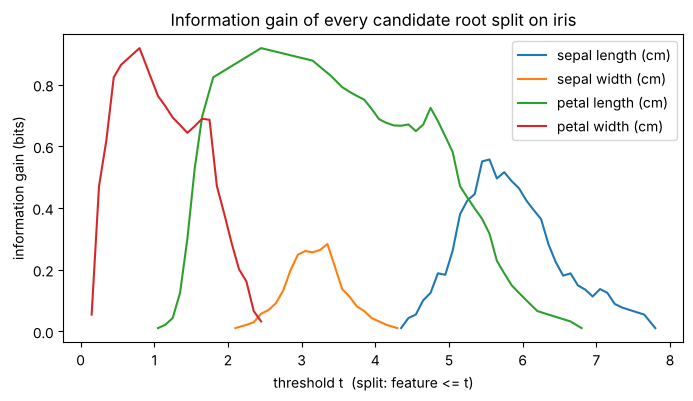

  best split on petal width (cm)  : <= 0.80   gain 0.9183 bits
  best split on petal length (cm) : <= 2.45   gain 0.9183 bits
  best split on sepal length (cm) : <= 5.55   gain 0.5572 bits
  best split on sepal width (cm)  : <= 3.35   gain 0.2831 bits

sklearn root split: petal width (cm) <= 0.80   (criterion='entropy')
our gain for that split: 0.9183 bits;  entropy at the root: 1.5850, children: [0. 1.]


In [16]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

iris = load_iris()
X, y = iris.data, iris.target
print(f"iris: H(species) = {entropy_of_labels(y):.4f} bits (three balanced classes = log2 3)")

best = []
plt.figure(figsize=(8, 4))
for j, fname in enumerate(iris.feature_names):
    vals = np.unique(X[:, j]); thresholds = (vals[:-1] + vals[1:]) / 2
    gains = np.array([information_gain(X[:, j] <= t, y) for t in thresholds])
    k = int(np.argmax(gains)); best.append((gains[k], j, thresholds[k]))
    plt.plot(thresholds, gains, label=fname)
plt.xlabel("threshold t  (split: feature <= t)"); plt.ylabel("information gain (bits)")
plt.title("Information gain of every candidate root split on iris"); plt.legend(); plt.show()

for g, j, t in sorted(best, reverse=True):
    print(f"  best split on {iris.feature_names[j]:18s}: <= {t:.2f}   gain {g:.4f} bits")

clf = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=0).fit(X, y)
j, t = clf.tree_.feature[0], clf.tree_.threshold[0]
print(f"\nsklearn root split: {iris.feature_names[j]} <= {t:.2f}   (criterion='entropy')")
print(f"our gain for that split: {information_gain(X[:, j] <= t, y):.4f} bits;  entropy at the root: {clf.tree_.impurity[0]:.4f}, children: {np.round(clf.tree_.impurity[1:], 4)}")

Low oxygen saturation beats fever by a factor of five, and both criteria agree. The *patient ID* feature
has the largest gain of all — one bit, the whole entropy — because it memorises each patient; its gain ratio
exposes the trick. On iris, two splits tie at $0.918$ bits (petal width $\le 0.8$ and petal length $\le 2.45$):
each isolates all 50 setosa flowers perfectly, leaving a 50/50 node with one bit of entropy, so the gain is
$\log_2 3 - \tfrac23 \cdot 1 = 0.918$. scikit-learn picks one of the two tied splits; which one depends on the
order in which it evaluates features.

**Try it yourself:** pass `gini_of_labels` as the impurity in the iris scan — does the ranking of the four
features change?

## 9. Language models: cross-entropy, perplexity and temperature

A model's per-token loss $\mathcal{L} = -\frac1T\sum_t \log p(x_t \mid x_{<t})$ (nats) has perplexity
$e^{\mathcal{L}}$, the "effective number of equally likely choices". Temperature rescales logits,
$p_T(k) \propto e^{z_k / T}$, moving along the maximum-entropy family of Section 7: $T \to 0$ is the argmax,
$T \to \infty$ is uniform. We sweep $T$ on a four-token vocabulary and demonstrate top-$k$ and top-$p$.

logits [ 2.  1.  0. -1.] -> softmax [0.6439 0.2369 0.0871 0.0321];  H = 1.3670 bits = 0.9475 nats;  perplexity 2^H = 2.5793
if the true next token is #2 (p = 0.2369): loss = 1.4402 nats = 2.0778 bits

     T                                 p(T)   H bits     PPL
  0.25 [9.817e-01 1.800e-02 3.000e-04 0.000e+00]   0.1343   1.098
  0.50        [0.865  0.1171 0.0158 0.0021]   0.6570   1.577
  1.00        [0.6439 0.2369 0.0871 0.0321]   1.3670   2.579
  2.00        [0.4551 0.276  0.1674 0.1015]   1.7962   3.473
  5.00        [0.3292 0.2695 0.2207 0.1807]   1.9645   3.903
100.00        [0.2538 0.2512 0.2487 0.2463]   1.9999   4.000
limits: T -> 0 gives H = 0 (greedy), T -> inf gives H = log2 V = 2.0 bits, PPL = V = 4


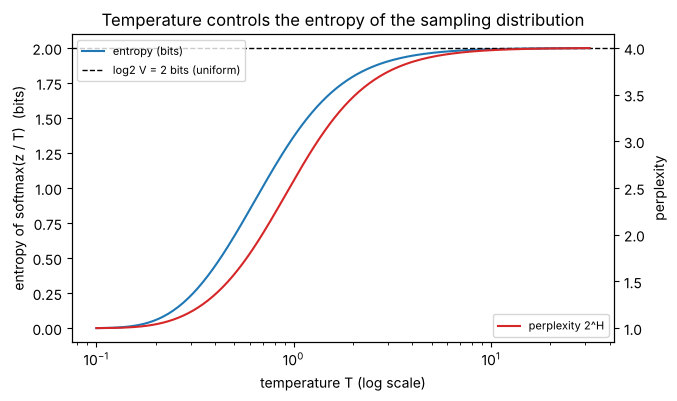

In [17]:
def softmax_T(z, T=1.0):
    z = np.asarray(z, dtype=float) / T
    e = np.exp(z - z.max())
    return e / e.sum()

def perplexity_from_probs(probs):
    probs = np.asarray(probs, dtype=float)
    return float(np.exp(-np.mean(np.log(probs))))

z = np.array([2.0, 1.0, 0.0, -1.0])
p1 = softmax_T(z)
print(f"logits {z} -> softmax {np.round(p1, 4)};  H = {entropy_bits(p1):.4f} bits = {entropy_bits(p1) * LN2:.4f} nats;  perplexity 2^H = {2**entropy_bits(p1):.4f}")
print(f"if the true next token is #2 (p = {p1[1]:.4f}): loss = {-np.log(p1[1]):.4f} nats = {-np.log2(p1[1]):.4f} bits")

print(f"\n{'T':>6s} {'p(T)':>36s} {'H bits':>8s} {'PPL':>7s}")
for T in (0.25, 0.5, 1, 2, 5, 100):
    pT = softmax_T(z, T)
    print(f"{T:6.2f} {str(np.round(pT, 4)):>36s} {entropy_bits(pT):8.4f} {2**entropy_bits(pT):7.3f}")
print(f"limits: T -> 0 gives H = 0 (greedy), T -> inf gives H = log2 V = {np.log2(4):.1f} bits, PPL = V = 4")

Ts = np.logspace(-1, 1.5, 200)
Hs = np.array([entropy_bits(softmax_T(z, T)) for T in Ts])
fig, ax1 = plt.subplots()
ax1.semilogx(Ts, Hs, label="entropy (bits)"); ax1.set_xlabel("temperature T (log scale)"); ax1.set_ylabel("entropy of softmax(z / T)  (bits)")
ax1.axhline(np.log2(4), color="k", ls="--", lw=1, label="log2 V = 2 bits (uniform)")
ax2 = ax1.twinx(); ax2.semilogx(Ts, 2**Hs, color="C3", label="perplexity 2^H"); ax2.set_ylabel("perplexity")
ax1.set_title("Temperature controls the entropy of the sampling distribution")
ax1.legend(loc="upper left", fontsize=8); ax2.legend(loc="lower right", fontsize=8); plt.show()

In [18]:
# top-k and top-p (nucleus) truncation at T = 1
def top_k(p, k):
    keep = np.argsort(p)[::-1][:k]; out = np.zeros_like(p); out[keep] = p[keep]; return out / out.sum()

def top_p(p, p_mass):
    order = np.argsort(p)[::-1]; cum = np.cumsum(p[order])
    n_keep = int(np.searchsorted(cum, p_mass) + 1)
    out = np.zeros_like(p); out[order[:n_keep]] = p[order[:n_keep]]; return out / out.sum()

print(f"sorted cumulative probabilities: {np.round(np.cumsum(np.sort(p1)[::-1]), 4)}")
for name, pp in [("full softmax", p1), ("top-k, k = 2", top_k(p1, 2)), ("top-p, p = 0.9", top_p(p1, 0.9)), ("T = 0.5", softmax_T(z, 0.5))]:
    print(f"  {name:16s} {str(np.round(pp, 4)):>36s}   H = {entropy_bits(pp):.4f} bits")

# the perplexity of a sequence is the inverse geometric mean of the probabilities assigned to the actual tokens
seq_probs = np.array([0.5, 0.1, 0.25, 0.05, 0.8])
L_nats = -np.mean(np.log(seq_probs))
print(f"\nsequence probabilities {seq_probs}: mean loss {L_nats:.4f} nats = {L_nats / LN2:.4f} bits/token;  perplexity {perplexity_from_probs(seq_probs):.4f}"
      f"  = 1 / geometric mean {np.exp(np.mean(np.log(seq_probs))):.4f}")
print("\nloss (nats/token) -> bits/token -> perplexity:")
for L in (1.0, 1.5, 2.0, 2.5, 3.0):
    print(f"  {L:.1f} -> {L / LN2:.3f} -> {np.exp(L):6.2f}")
print(f"uniform over a 50,000-token vocabulary: loss = ln 50000 = {np.log(50_000):.2f} nats, PPL = 50,000")
print(f"a loss of 2.0 nats/token at 4 bytes/token = {2.0 / LN2 / 4:.3f} bits per byte  ({100 * 2.0 / LN2 / 4 / 8:.0f}% of the raw 8 bits)")

from scipy.special import softmax as sp_softmax
print(f"\nscipy.special.softmax(z / 2) agrees with softmax_T(z, 2): {np.allclose(sp_softmax(z / 2), softmax_T(z, 2))}")

sorted cumulative probabilities: [0.6439 0.8808 0.9679 1.    ]
  full softmax            [0.6439 0.2369 0.0871 0.0321]   H = 1.3670 bits
  top-k, k = 2            [0.7311 0.2689 0.     0.    ]   H = 0.8399 bits
  top-p, p = 0.9          [0.6652 0.2447 0.09   0.    ]   H = 1.2009 bits
  T = 0.5                 [0.865  0.1171 0.0158 0.0021]   H = 0.6570 bits

sequence probabilities [0.5  0.1  0.25 0.05 0.8 ]: mean loss 1.5202 nats = 2.1932 bits/token;  perplexity 4.5731  = 1 / geometric mean 0.2187

loss (nats/token) -> bits/token -> perplexity:
  1.0 -> 1.443 ->   2.72
  1.5 -> 2.164 ->   4.48
  2.0 -> 2.885 ->   7.39
  2.5 -> 3.607 ->  12.18
  3.0 -> 4.328 ->  20.09
uniform over a 50,000-token vocabulary: loss = ln 50000 = 10.82 nats, PPL = 50,000
a loss of 2.0 nats/token at 4 bytes/token = 0.721 bits per byte  (9% of the raw 8 bits)

scipy.special.softmax(z / 2) agrees with softmax_T(z, 2): True


Lowering $T$ sharpens *every* token's probability uniformly; top-$k$ and top-$p$ instead cut the tail and
leave the head's proportions intact — a different way to lower entropy, aimed at the region where a model's
small probabilities are least trustworthy. The perplexity of a sequence is the inverse geometric mean of the
probabilities the model gave to what actually happened; a single near-zero probability dominates it, which
is why one confidently wrong prediction can ruin an evaluation.

**Try it yourself:** append a fifth logit of $-6$ to `z` — the entropy at $T = 1$ barely moves, but the
$T \to \infty$ limit rises to $\log_2 5$. What does that say about rare tokens and high temperatures?

## 10. Channel capacity: the binary symmetric channel

A channel flips each bit with probability $p$. Its capacity is $C = 1 - H_b(p)$ bits per use: below that rate
reliable communication is possible with long codes, above it impossible. We plot the capacity and simulate
repetition codes, which buy reliability only by throwing away rate.

BSC with p = 0.1: capacity C = 1 - H_b(0.1) = 0.5310 bits per channel use
          code   rate  bit error (exact)  simulated
      raw bits  1.000            0.10000    0.09965
     repeat x3  0.333            0.02800    0.02786
     repeat x5  0.200            0.00856    0.00869
     repeat x7  0.143            0.00273    0.00253
     repeat x9  0.111            0.00089    0.00089

at p = 0.01: capacity 0.9192;  Hamming(7,4) rate 4/7 = 0.571, block error 0.0020 vs 0.0394 for 4 raw bits


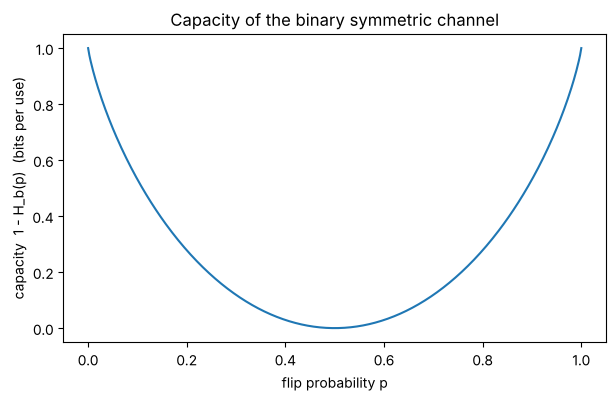

In [19]:
from math import comb

def bsc_capacity(p):
    return 1 - binary_entropy(p)

def repetition_error_exact(p, r):
    # majority vote over r copies fails when more than half flip
    return sum(comb(r, k) * p**k * (1 - p)**(r - k) for k in range(r // 2 + 1, r + 1))

def repetition_error_simulated(p, r, n_bits, rng):
    flips = rng.random((n_bits, r)) < p
    return float((flips.sum(axis=1) > r // 2).mean())

p_flip = 0.1
print(f"BSC with p = {p_flip}: capacity C = 1 - H_b({p_flip}) = {bsc_capacity(p_flip):.4f} bits per channel use")
print(f"{'code':>14s} {'rate':>6s} {'bit error (exact)':>18s} {'simulated':>10s}")
print(f"{'raw bits':>14s} {1.0:6.3f} {p_flip:18.5f} {repetition_error_simulated(p_flip, 1, 200_000, rng):10.5f}")
for r in (3, 5, 7, 9):
    print(f"{'repeat x' + str(r):>14s} {1/r:6.3f} {repetition_error_exact(p_flip, r):18.5f} {repetition_error_simulated(p_flip, r, 200_000, rng):10.5f}")

p_ham = 0.01
block_raw = 1 - (1 - p_ham)**4
block_hamming = 1 - ((1 - p_ham)**7 + 7 * p_ham * (1 - p_ham)**6)
print(f"\nat p = {p_ham}: capacity {bsc_capacity(p_ham):.4f};  Hamming(7,4) rate 4/7 = {4/7:.3f}, block error {block_hamming:.4f} vs {block_raw:.4f} for 4 raw bits")

ps = np.linspace(0, 1, 401)
plt.plot(ps, [bsc_capacity(p) for p in ps])
plt.xlabel("flip probability p"); plt.ylabel("capacity  1 - H_b(p)  (bits per use)")
plt.title("Capacity of the binary symmetric channel"); plt.show()

The capacity curve is the mirror image of the binary entropy: a channel that flips half the bits carries
nothing, and a channel that flips *all* of them is perfect (just invert the output). Repetition codes
reduce the error from $0.1$ to $0.0086$ at the price of one fifth of the rate, while capacity says rates up
to $0.53$ are achievable with vanishing error. The codes that approach it — Hamming, then LDPC and polar codes
— spend their redundancy on *structure* rather than copies.

## Summary

- Information is surprise, $-\log p$; the logarithm is forced by additivity over independent events; bits and nats differ by the factor $\ln 2$.
- Entropy is expected surprise: maximal for uniform distributions, zero for certainty; $H(X, Y) = H(X) + H(Y \mid X)$; differential entropy is only meaningful in differences.
- Huffman codes come within one bit of the entropy, arithmetic coding within two bits for a whole sequence — a model's log-loss *is* a compression rate.
- Cross-entropy $= H(p) + D_{\mathrm{KL}}(p \,\|\, q)$; KL is non-negative, asymmetric and infinite for impossible events; forward KL covers modes, reverse KL seeks one.
- Mutual information detects any dependence, is estimated with an upward bias from binned data, and should be compared with a shuffle null.
- Jensen's inequality gives the ELBO, whose gap is exactly the KL divergence to the true posterior.
- Maximum entropy under moment constraints yields exponential families; the softmax is the max-ent distribution with a fixed expected score, and temperature moves along that family.
- Information gain is mutual information between label and split; the gain ratio guards against many-valued features.
- Perplexity $= e^{\text{loss}}$ is an effective branching factor; temperature, top-$k$ and top-$p$ reshape the entropy of the sampling distribution.
- Channel capacity $1 - H_b(p)$ bounds reliable communication; codes approach it with structure, not repetition.

**Next:** open `exercises.ipynb` and work through the self-checked problems; the solutions notebook has reference implementations.